<a href="https://colab.research.google.com/github/cotnee/SkyBlink/blob/main/pipeline/engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SPHEREx Shift-and-Stack: finding moving objects that no single image can show

**NASA Space Apps Challenge 2026: Planet X and SPHEREx**

Existing tools ask people to find what is visible. This pipeline finds faint moving objects that are invisible in every individual SPHEREx exposure, rejects artifacts automatically, and estimates what each object is from its colors.

**Pipeline**
1. **Find:** shift-and-stack. For many possible velocities, shift all exposures as if tracking a moving object and add them up. Noise averages out; an object moving at that velocity adds up into a clear point.
2. **Verify:** automatic checks (image edges, residuals of bright stars, signal present in both halves of the observations), plus injection-recovery tests with artificial objects to measure sensitivity.
3. **Understand:** each SPHEREx detector sees a different wavelength, so measuring brightness along the found track gives a 6-color spectrum for free.

**How to run:** Runtime → Run all. Downloaded data are cached on Google Drive, so the archive is only queried once per field.

**AI use:** code was written with the help of Claude (Anthropic).

## 1. Setup

In [1]:
!pip -q install astroquery reproject

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, time, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from scipy.ndimage import binary_dilation, distance_transform_edt, maximum_filter
from matplotlib.animation import FuncAnimation, PillowWriter

from google.colab import drive
drive.mount("/content/drive")

# ---- Field settings ----
FIELD_NAME = "barnard"          # short name, used in file names
ra, dec = 269.448, 4.770        # field centre, degrees (Barnard's Star, 2026)
PASS = 2                        # which survey pass to use: 0, 1 or 2
N, PIXEL_ARCSEC = 60, 6.15      # output grid: 60 x 60 pixels, SPHEREx pixel scale

DATA_DIR = "/content/drive/MyDrive/spherex_data"
OUT = "/content/drive/MyDrive/spherex_site"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


## 2. Which SPHEREx exposures cover this field?

In [3]:
query = f'''
SELECT a.uri, p.time_bounds_lower, p.energy_bandpassname
FROM spherex.artifact a
JOIN spherex.plane p ON a.planeid = p.planeid
WHERE 1 = CONTAINS(POINT('ICRS', {ra}, {dec}), p.poly)
ORDER BY p.time_bounds_lower
'''
res = Irsa.query_tap(query).to_table()
mjd = np.array(res["time_bounds_lower"], dtype=float)
print("Exposures covering the field:", len(res))

# Split into survey passes: a new pass starts after a gap of more than 30 days
visit = np.concatenate([[0], np.cumsum(np.diff(mjd) > 30)])
for v in np.unique(visit):
    m = mjd[visit == v]
    print(f"Pass {v}: {len(m)} exposures, "
          f"{Time(m.min(), format='mjd').iso[:10]} to {Time(m.max(), format='mjd').iso[:10]}")
print("Exposures per detector:", dict(Counter(res["energy_bandpassname"])))

Exposures covering the field: 358
Pass 0: 118 exposures, 2025-08-15 to 2025-10-01
Pass 1: 121 exposures, 2026-03-11 to 2026-05-05
Pass 2: 119 exposures, 2026-08-16 to 2026-09-22
Exposures per detector: {'SPHEREx-D6': 58, 'SPHEREx-D3': 59, 'SPHEREx-D5': 61, 'SPHEREx-D2': 61, 'SPHEREx-D1': 60, 'SPHEREx-D4': 59}


## 3. Download cutouts and align them on one sky grid (cached on Drive)

In [5]:
import shutil
shutil.copy("/content/drive/MyDrive/barnard_pass3.npz",
            f"{DATA_DIR}/{FIELD_NAME}_pass{PASS}.npz")
print("Copied")

Copied


Loaded from Drive: /content/drive/MyDrive/spherex_data/barnard_pass2.npz
Aligned exposures: 119


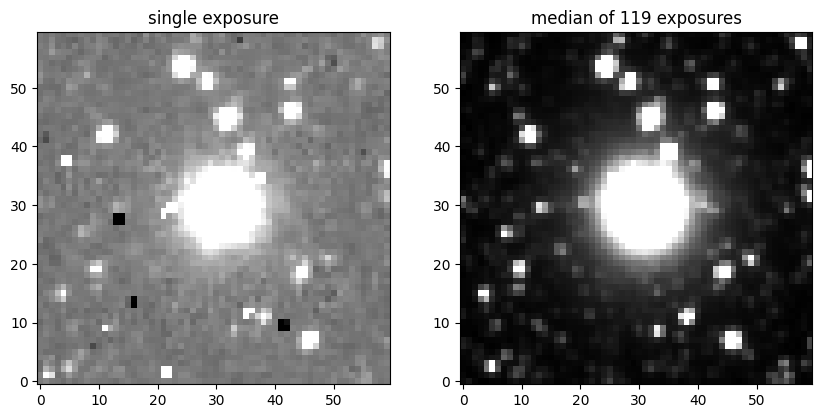

In [6]:
# Common grid: north up, SPHEREx pixel scale
scale = PIXEL_ARCSEC / 3600
target = WCS(naxis=2)
target.wcs.ctype = ["RA---TAN", "DEC--TAN"]
target.wcs.crval = [ra, dec]
target.wcs.crpix = [N / 2 + 0.5, N / 2 + 0.5]
target.wcs.cdelt = [-scale, scale]

def load_aligned(row, size_deg=0.12):
    url = (f"https://irsa.ipac.caltech.edu/{str(row['uri']).lstrip('/')}"
           f"?center={ra},{dec}&size={size_deg}")
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with fits.open(url, cache=False) as h:
                data = h["IMAGE"].data.astype(float)
                w = WCS(h["IMAGE"].header)
            img, _ = reproject_interp((data, w), target, shape_out=(N, N))
        return img - np.nanmedian(img)          # remove frame background
    except Exception as e:
        print("skipped:", str(e)[:80])
        return None

def load_retry(row, tries=5):
    for attempt in range(tries):
        img = load_aligned(row)
        if img is not None:
            return img
        time.sleep(5 * (attempt + 1))           # the archive is busy: wait longer each time
    return None

cache = f"{DATA_DIR}/{FIELD_NAME}_pass{PASS}.npz"
if os.path.exists(cache):
    d = np.load(cache)
    cube, times, bands = d["cube"], d["times"], d["bands"].astype(str)
    print("Loaded from Drive:", cache)
else:
    sel = visit == PASS
    rows, t_sel = res[sel], mjd[sel]
    with ThreadPoolExecutor(2) as ex:           # only 2 parallel downloads: the archive is busy
        imgs = list(ex.map(load_retry, rows))
    ok = [i for i, x in enumerate(imgs) if x is not None]
    cube = np.array([imgs[i] for i in ok])
    times = t_sel[ok]
    bands = np.array(rows["energy_bandpassname"]).astype(str)[ok]
    np.savez(cache, cube=cube, times=times, bands=bands)
    print("Saved to Drive:", cache)
print("Aligned exposures:", len(cube))

stack = np.nanmedian(cube, axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in [(axes[0], cube[0], "single exposure"),
                       (axes[1], stack, f"median of {len(cube)} exposures")]:
    lo, hi = ZScaleInterval().get_limits(img)
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
plt.show()

## 4. Core functions: injection, preparation, shift-and-stack

In [7]:
def mad_std(a):
    # Robust noise estimate that ignores stars and outliers
    return 1.4826 * np.nanmedian(np.abs(a - np.nanmedian(a)))

def inject(cube, times, x0, y0, vx, vy, amp_sigma=1.5, psf_sigma=0.8):
    # Add an artificial moving object: start (x0, y0), velocity in pixels/day,
    # brightness in units of the single-exposure noise.
    out = cube.copy()
    yy, xx = np.mgrid[:cube.shape[1], :cube.shape[2]]
    dt = times - times.min()
    for k in range(len(cube)):
        x, y = x0 + vx * dt[k], y0 + vy * dt[k]
        psf = np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * psf_sigma ** 2))
        out[k] += amp_sigma * mad_std(cube[k]) * psf
    return out

def prepare(cube, bands, clip=5.0):
    z = np.full_like(cube, np.nan)
    # 1. Static-sky template per detector (each detector sees a different color)
    for b in np.unique(bands):
        sel = bands == b
        z[sel] = cube[sel] - np.nanmedian(cube[sel], axis=0)
    # 2. Mask bright stars
    template = np.nanmedian(cube, axis=0)
    mask = binary_dilation(template > 5 * mad_std(template), iterations=1)
    z[:, mask] = np.nan
    # 3. Normalise noise to 1 and drop bad exposures
    s = np.array([mad_std(f) for f in z])
    filled = np.mean(np.isfinite(z), axis=(1, 2))
    good = np.isfinite(s) & (s > 0) & (filled > 0.3)
    z = z[good] / s[good, None, None]
    # 4. Clip cosmic rays and hot pixels
    z = np.clip(z, -clip, clip)
    return z, mask, good

def shift_img(img, dy, dx):
    # Shift without wrapping around the edges; empty pixels become NaN
    H, W = img.shape
    out = np.full_like(img, np.nan)
    if abs(dy) >= H or abs(dx) >= W:
        return out
    out[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = \
        img[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return out

def shift_stack_ref(z, times, vx, vy, t_ref):
    # Shift exposures against the assumed motion and add them.
    # Output: significance map, positions given at time t_ref.
    dt = times - t_ref
    acc = np.zeros(z.shape[1:]); n = np.zeros(z.shape[1:])
    for k in range(len(z)):
        f = shift_img(z[k], int(round(-vy * dt[k])), int(round(-vx * dt[k])))
        acc += np.nan_to_num(f); n += np.isfinite(f)
    out = acc / np.sqrt(np.maximum(n, 1))
    out[n < 0.5 * len(z)] = np.nan                                  # too few exposures
    out[:3, :] = out[-3:, :] = out[:, :3] = out[:, -3:] = np.nan    # image edges
    return out

def shift_stack(z, times, vx, vy):
    return shift_stack_ref(z, times, vx, vy, times.min())

vs = np.arange(-0.5, 0.51, 0.05)   # velocity grid, pixels/day

## 5. Test: can the pipeline find an injected object that is invisible in single exposures?

Exposures after quality cuts: 119 of 119
Found: vx=0.30, vy=-0.10, significance 12.7, position (12, 50)
True:  vx=0.25, vy=-0.1, position (12, 50)


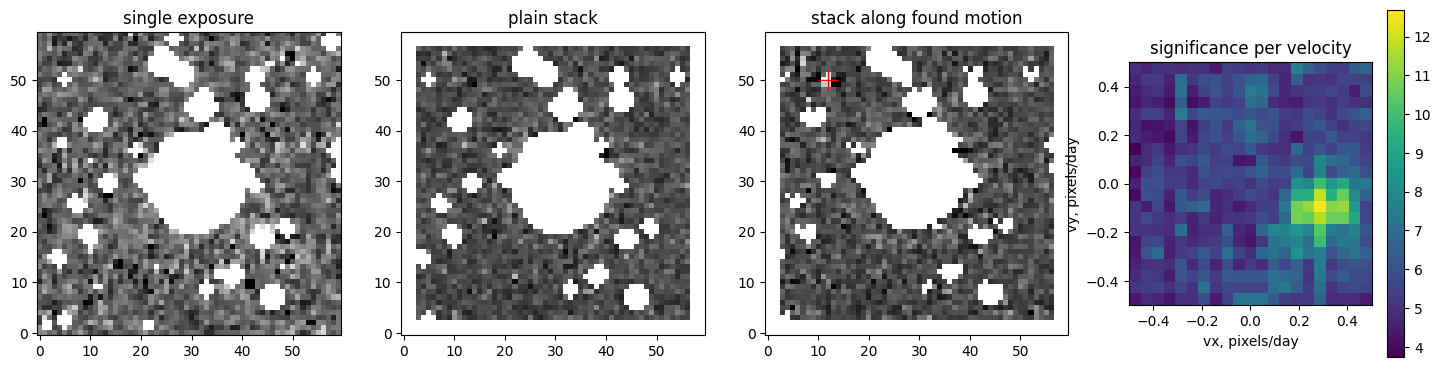

In [8]:
true_vx, true_vy, x0, y0 = 0.25, -0.10, 12, 50
fake = inject(cube, times, x0, y0, true_vx, true_vy)
z, mask, good = prepare(fake, bands)
tz = times[good]
print("Exposures after quality cuts:", len(z), "of", len(cube))

best = np.array([[np.nanmax(shift_stack(z, tz, vx, vy)) for vx in vs] for vy in vs])
iy, ix = np.unravel_index(np.nanargmax(best), best.shape)
img = shift_stack(z, tz, vs[ix], vs[iy])
py, px = np.unravel_index(np.nanargmax(img), img.shape)
print(f"Found: vx={vs[ix]:.2f}, vy={vs[iy]:.2f}, significance {np.nanmax(best):.1f}, position ({px}, {py})")
print(f"True:  vx={true_vx}, vy={true_vy}, position ({x0}, {y0})")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(z[0], origin="lower", cmap="gray", vmin=-3, vmax=5)
axes[0].set_title("single exposure")
axes[1].imshow(shift_stack(z, tz, 0, 0), origin="lower", cmap="gray", vmin=-3, vmax=8)
axes[1].set_title("plain stack")
axes[2].imshow(img, origin="lower", cmap="gray", vmin=-3, vmax=8)
axes[2].plot(px, py, "r+", ms=15)
axes[2].set_title("stack along found motion")
im = axes[3].imshow(best, origin="lower", extent=[vs[0], vs[-1], vs[0], vs[-1]])
axes[3].set_title("significance per velocity")
axes[3].set_xlabel("vx, pixels/day"); axes[3].set_ylabel("vy, pixels/day")
plt.colorbar(im, ax=axes[3])
plt.show()

## 6. Brightest candidate in the real data (no injected objects)

Candidate: position (41, 29), velocity (0.10, -0.20) pixels/day = 1.4 arcsec/day, significance 7.9
Distance to nearest star mask: 0.0 pixels
Halves in time (a real object gives ~5.6 in both): 3.3 and 4.7
Per detector (a real object is spread out, ~3.2 each): {'D1': 3.3, 'D2': 7.1, 'D3': 1.2, 'D4': 2.8, 'D5': 3.4, 'D6': 0.2}
Known Solar System objects nearby:
<No columns>


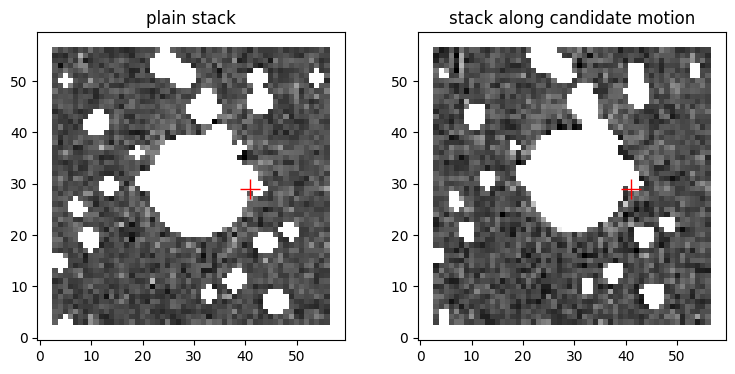

In [9]:
z0, mask0, g0 = prepare(cube, bands)
t0, b0 = times[g0], bands[g0]
tref = t0.min()

noise0 = np.array([[np.nanmax(shift_stack_ref(z0, t0, vx, vy, tref)) for vx in vs] for vy in vs])
iy0, ix0 = np.unravel_index(np.nanargmax(noise0), noise0.shape)
cvx, cvy = vs[ix0], vs[iy0]
cimg = shift_stack_ref(z0, t0, cvx, cvy, tref)
cy, cx = np.unravel_index(np.nanargmax(cimg), cimg.shape)
print(f"Candidate: position ({cx}, {cy}), velocity ({cvx:.2f}, {cvy:.2f}) pixels/day "
      f"= {np.hypot(cvx, cvy) * PIXEL_ARCSEC:.1f} arcsec/day, significance {cimg[cy, cx]:.1f}")
print("Distance to nearest star mask:", round(distance_transform_edt(~mask0)[cy, cx], 1), "pixels")

def sig_at(idx):
    im = shift_stack_ref(z0[idx], t0[idx], cvx, cvy, tref)
    return np.nanmax(im[max(cy - 1, 0):cy + 2, max(cx - 1, 0):cx + 2])

order = np.argsort(t0)
h = len(order) // 2
s_all = cimg[cy, cx]
print(f"Halves in time (a real object gives ~{s_all / 1.41:.1f} in both): "
      f"{sig_at(order[:h]):.1f} and {sig_at(order[h:]):.1f}")
print(f"Per detector (a real object is spread out, ~{s_all / 2.45:.1f} each):",
      {str(b)[-2:]: round(float(sig_at(np.where(b0 == b)[0])), 1) for b in np.unique(b0)})

try:
    from astroquery.imcce import Skybot
    r = Skybot.cone_search(target.pixel_to_world(cx, cy), 2 * u.arcmin, Time(tref, format="mjd"))
    print("Known Solar System objects nearby:"); print(r[:5])
except Exception as e:
    print("SkyBoT:", str(e)[:120])

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, im, ttl in [(ax[0], shift_stack_ref(z0, t0, 0, 0, tref), "plain stack"),
                   (ax[1], cimg, "stack along candidate motion")]:
    a.imshow(im, origin="lower", cmap="gray", vmin=-3, vmax=8)
    a.plot(cx, cy, "r+", ms=15); a.set_title(ttl)
plt.show()

## 7. Detection threshold and sensitivity (injection-recovery test)

Detection threshold (brightest noise peak): 7.7
brightness 2.0: found 8 of 11
brightness 1.5: found 9 of 12
brightness 1.0: found 2 of 10
brightness 0.7: found 0 of 10
brightness 0.5: found 1 of 11
brightness 0.35: found 0 of 11


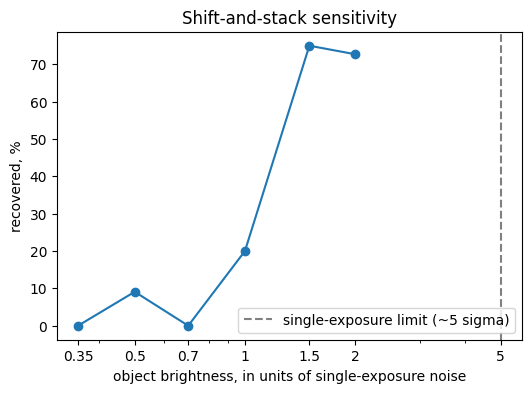

In [10]:
# 1. Remove the candidate's track and measure the real noise level
zn = z0.copy()
yy, xx = np.mgrid[:zn.shape[1], :zn.shape[2]]
for k in range(len(zn)):
    dt = t0[k] - tref
    zn[k][(xx - (cx + cvx * dt)) ** 2 + (yy - (cy + cvy * dt)) ** 2 < 9] = np.nan
noise = np.array([[np.nanmax(shift_stack_ref(zn, t0, vx, vy, tref)) for vx in vs] for vy in vs])
thr = np.nanmax(noise)
print(f"Detection threshold (brightest noise peak): {thr:.1f}")

# 2. Inject objects whose whole track stays inside the image
T = times.max() - times.min()
rng = np.random.default_rng(1)
amps = [2.0, 1.5, 1.0, 0.7, 0.5, 0.35]
rates = []
for a in amps:
    hits = valid = 0
    for _ in range(12):
        vx, vy = rng.uniform(-0.3, 0.3, 2)
        x0 = rng.uniform(max(5, 5 - vx * T), min(55, 55 - vx * T))
        y0 = rng.uniform(max(5, 5 - vy * T), min(55, 55 - vy * T))
        z, _, g = prepare(inject(cube, times, x0, y0, vx, vy, amp_sigma=a), bands)
        img = shift_stack_ref(z, times[g], vx, vy, times.min())
        xi, yi = int(round(x0)), int(round(y0))
        patch = img[max(yi - 1, 0):yi + 2, max(xi - 1, 0):xi + 2]
        if np.all(np.isnan(patch)):
            continue
        valid += 1; hits += np.nanmax(patch) > thr
    rates.append(100 * hits / max(valid, 1))
    print(f"brightness {a}: found {hits} of {valid}")

plt.figure(figsize=(6, 4))
plt.plot(amps, rates, "o-")
plt.axvline(5, ls="--", color="gray", label="single-exposure limit (~5 sigma)")
plt.xscale("log")
plt.xticks([0.35, 0.5, 0.7, 1, 1.5, 2, 5], ["0.35", "0.5", "0.7", "1", "1.5", "2", "5"])
plt.xlabel("object brightness, in units of single-exposure noise"); plt.ylabel("recovered, %")
plt.title("Shift-and-stack sensitivity"); plt.legend(); plt.show()

## 8. Full automatic pipeline: candidates, checks, 6-color spectrum, files for the website

barnard_cand_1: (45, 12), significance 11.8, demo=True, candidate  | normal color: similar to an asteroid in reflected sunlight, or a star
barnard_cand_2: (12, 50), significance 9.8, demo=True, candidate  | very red: similar to a cold brown dwarf or a distant cold body
barnard_cand_3: (41, 29), significance 7.9, demo=False, rejected ['next to a bright-star mask: likely a star residual'] | normal color: similar to an asteroid in reflected sunlight, or a star
barnard_cand_4: (39, 23), significance 7.7, demo=False, rejected ['next to a bright-star mask: likely a star residual', 'signal present in only one half of the observations'] | normal color: similar to an asteroid in reflected sunlight, or a star
Saved to /content/drive/MyDrive/spherex_site : ['barnard_cand_1.gif', 'barnard_cand_1.png', 'barnard_cand_2.gif', 'barnard_cand_2.png', 'barnard_cand_3.gif', 'barnard_cand_3.png', 'barnard_cand_4.gif', 'barnard_cand_4.png', 'cand_1.gif', 'cand_1.png', 'cand_2.gif', 'cand_2.png', 'cand_3.gif

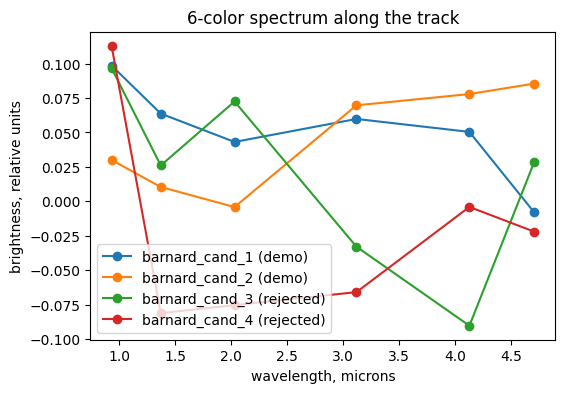

In [11]:
WAVE = {"D1": 0.93, "D2": 1.37, "D3": 2.03, "D4": 3.12, "D5": 4.13, "D6": 4.71}  # detector centre, microns

def inject_sed(cube, times, bands, x0, y0, vx, vy, factors, base=1.0, psf_sigma=0.8):
    # Add an artificial object with its own color: factors = brightness in each detector
    out = cube.copy()
    noise = np.nanmedian([mad_std(f) for f in cube])
    yy, xx = np.mgrid[:cube.shape[1], :cube.shape[2]]
    dt = times - times.min()
    for k in range(len(cube)):
        x, y = x0 + vx * dt[k], y0 + vy * dt[k]
        a = factors[str(bands[k])[-2:]] * base * noise
        out[k] += a * np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * psf_sigma ** 2))
    return out

def find_candidates(z, t, thr, top=5):
    # Blind search: peaks above threshold for every velocity, duplicates removed
    tr, found = t.min(), []
    for vy in vs:
        for vx in vs:
            im = shift_stack_ref(z, t, vx, vy, tr)
            im2 = np.nan_to_num(im, nan=-99.0)
            pk = (im2 == maximum_filter(im2, size=5)) & (im2 > thr)
            for y, x in zip(*np.nonzero(pk)):
                found.append(dict(x=int(x), y=int(y), vx=round(float(vx), 2),
                                  vy=round(float(vy), 2), sig=round(float(im[y, x]), 1)))
    found.sort(key=lambda c: -c["sig"])
    uniq = []
    for c in found:   # one object peaks at neighbouring velocities too: keep the strongest
        if all(abs(c["x"] - q["x"]) > 3 or abs(c["y"] - q["y"]) > 3 for q in uniq):
            uniq.append(c)
    return uniq[:top]

def check(c, z, t, mask):
    # Automatic checks: significance in each half of the observations and rejection reasons
    tr = t.min()
    def s(idx):
        im = shift_stack_ref(z[idx], t[idx], c["vx"], c["vy"], tr)
        p = im[max(c["y"] - 1, 0):c["y"] + 2, max(c["x"] - 1, 0):c["x"] + 2]
        return round(float(np.nanmax(p)), 1) if np.isfinite(p).any() else 0.0
    o = np.argsort(t); h = len(o) // 2
    halves = [s(o[:h]), s(o[h:])]
    reasons = []
    if distance_transform_edt(~mask)[c["y"], c["x"]] < 2:
        reasons.append("next to a bright-star mask: likely a star residual")
    if min(halves) < 0.35 * c["sig"]:
        reasons.append("signal present in only one half of the observations")
    return halves, reasons

def sed(cube, t, b, c):
    # Brightness along the track, median per detector (6 colors)
    tr = t.min()
    d = np.full_like(cube, np.nan)
    for k in np.unique(b):
        sel = b == k
        d[sel] = cube[sel] - np.nanmedian(cube[sel], axis=0)
    out = {}
    for k in np.unique(b):
        f = []
        for i in np.where(b == k)[0]:
            x = int(round(c["x"] + c["vx"] * (t[i] - tr)))
            y = int(round(c["y"] + c["vy"] * (t[i] - tr)))
            if 1 <= x < cube.shape[2] - 1 and 1 <= y < cube.shape[1] - 1:
                f.append(np.nansum(d[i, y - 1:y + 2, x - 1:x + 2]))
        out[str(k)[-2:]] = round(float(np.nanmedian(f)), 4) if f else None
    return out

def classify(s):
    blue = [s[k] for k in ("D1", "D2") if s.get(k) is not None]
    red = [s[k] for k in ("D5", "D6") if s.get(k) is not None]
    if not blue or not red:
        return "not enough data for a color"
    b_, r_ = np.mean(blue), np.mean(red)
    if r_ > 0 and r_ > 3 * max(b_, 0):
        return "very red: similar to a cold brown dwarf or a distant cold body"
    return "normal color: similar to an asteroid in reflected sunlight, or a star"

def save_visuals(cid, z, t, c):
    tr, X, Y = t.min(), c["x"], c["y"]
    crop = lambda im: im[max(Y - 12, 0):Y + 13, max(X - 12, 0):X + 13]
    o = np.argsort(t)
    panels = [crop(z[o[len(o) // 2]]),
              crop(shift_stack_ref(z, t, 0, 0, tr)),
              crop(shift_stack_ref(z, t, c["vx"], c["vy"], tr))]
    fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
    for a, im, ttl in zip(ax, panels, ["single exposure", "plain stack", "stack along motion"]):
        a.imshow(im, origin="lower", cmap="gray", vmin=-3, vmax=8); a.set_title(ttl); a.axis("off")
    plt.tight_layout(); fig.savefig(f"{OUT}/{cid}.png", dpi=110); plt.close(fig)
    # Animation: the object emerges as more exposures are added
    steps = np.linspace(6, len(o), 12).astype(int)
    fig, a = plt.subplots(figsize=(3.2, 3.4)); a.axis("off")
    art = a.imshow(panels[2], origin="lower", cmap="gray", vmin=-3, vmax=8)
    def upd(i):
        n = steps[i]
        art.set_data(crop(shift_stack_ref(z[o[:n]], t[o[:n]], c["vx"], c["vy"], tr)))
        a.set_title(f"exposures stacked: {n}")
        return [art]
    FuncAnimation(fig, upd, frames=len(steps)).save(f"{OUT}/{cid}.gif", writer=PillowWriter(fps=3))
    plt.close(fig)

# --- Demo: two artificial objects with different colors ---
DEMO = [dict(x0=12, y0=50, vx=0.25, vy=-0.10,
             f={"D1": 0.1, "D2": 0.3, "D3": 0.6, "D4": 1.5, "D5": 3.0, "D6": 3.0}),   # red
        dict(x0=45, y0=12, vx=-0.20, vy=0.15,
             f={"D1": 2.0, "D2": 1.8, "D3": 1.5, "D4": 1.2, "D5": 1.0, "D6": 1.0})]   # normal
work = cube.copy()
for d_ in DEMO:
    work = inject_sed(work, times, bands, d_["x0"], d_["y0"], d_["vx"], d_["vy"], d_["f"])

# --- Full automatic pipeline ---
z, m, g = prepare(work, bands)
t, b, c3 = times[g], bands[g], work[g]
cands = []
for j, c in enumerate(find_candidates(z, t, thr)):
    cid = f"{FIELD_NAME}_cand_{j + 1}"
    halves, reasons = check(c, z, t, m)
    s = sed(c3, t, b, c)
    sky = target.pixel_to_world(c["x"], c["y"])
    is_demo = any(abs(c["x"] - d_["x0"]) <= 2 and abs(c["y"] - d_["y0"]) <= 2 for d_ in DEMO)
    save_visuals(cid, z, t, c)
    cands.append(dict(
        id=cid, demo=is_demo, ra=round(float(sky.ra.deg), 5), dec=round(float(sky.dec.deg), 5),
        date_ref=Time(t.min(), format="mjd").iso[:10], **c,
        speed_arcsec_day=round(float(np.hypot(c["vx"], c["vy"]) * PIXEL_ARCSEC), 2),
        halves=halves, verdict="candidate" if not reasons else "rejected", reasons=reasons,
        sed=s, sed_wave_um={k: WAVE[k] for k in s}, color_class=classify(s),
        image=f"{cid}.png", animation=f"{cid}.gif"))
    print(f"{cid}: ({c['x']}, {c['y']}), significance {c['sig']}, demo={is_demo}, "
          f"{cands[-1]['verdict']} {reasons if reasons else ''} | {cands[-1]['color_class']}")

with open(f"{OUT}/candidates.json", "w", encoding="utf-8") as f:
    json.dump(dict(field=dict(name=FIELD_NAME, ra=ra, dec=dec,
                              exposures=int(len(t)), threshold=round(float(thr), 1),
                              dates=[Time(t.min(), format="mjd").iso[:10],
                                     Time(t.max(), format="mjd").iso[:10]]),
                   candidates=cands), f, ensure_ascii=False, indent=1)
print("Saved to", OUT, ":", sorted(os.listdir(OUT)))

plt.figure(figsize=(6, 4))
for c in cands:
    ks = [k for k in WAVE if c["sed"].get(k) is not None]
    plt.plot([WAVE[k] for k in ks], [c["sed"][k] for k in ks], "o-",
             label=f"{c['id']} ({'demo' if c['demo'] else c['verdict']})")
plt.xlabel("wavelength, microns"); plt.ylabel("brightness, relative units")
plt.title("6-color spectrum along the track"); plt.legend(); plt.show()

In [12]:
for f in os.listdir(OUT):
    if f.startswith("cand_"):
        os.remove(f"{OUT}/{f}")
print(sorted(os.listdir(OUT)))

['barnard_cand_1.gif', 'barnard_cand_1.png', 'barnard_cand_2.gif', 'barnard_cand_2.png', 'barnard_cand_3.gif', 'barnard_cand_3.png', 'barnard_cand_4.gif', 'barnard_cand_4.png', 'candidates.json']


Proper motion: -802, 10362 mas/yr
Expected shift 2010.5 -> 2026.6: 168 arcsec = 27 SPHEREx pixels
WISE images found: 28
WISE W1 vs SPHEREx D4: measured 169 arcsec, expected 168
WISE W2 vs SPHEREx D6: measured 167 arcsec, expected 168


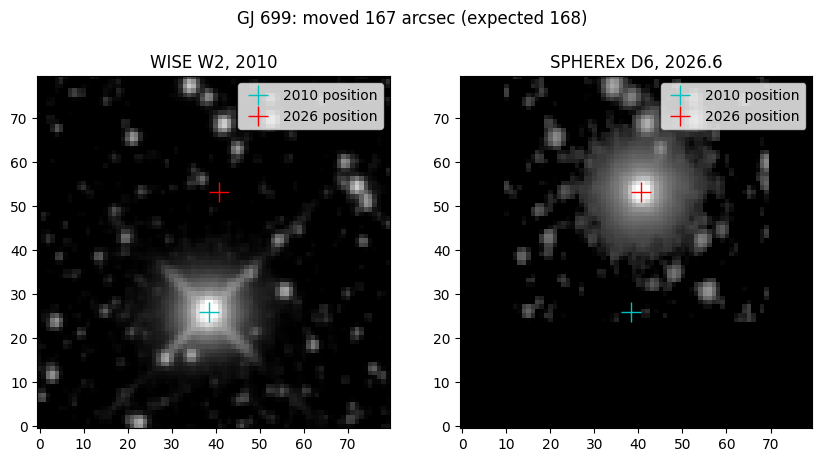

Saved: ['f01.png', 'f02.png', 'manifest.json']
Saved blink.gif


In [16]:
# ===== 9. Slow movers (Time Machine): WISE 2010 vs SPHEREx 2026 =====
from astroquery.simbad import Simbad
from astropy.coordinates import SkyCoord

SITE = "/content/drive/MyDrive/spherex_site/data"
TNAME, TID = "GJ 699", "barnard"      # SIMBAD name, folder name


# 1. Known motion (Gaia DR3 values; SIMBAD is unavailable today)
ra0, dec0, EP0 = 269.448503, 4.739420, 2016.0   # Barnard's Star at epoch 2016.0
pmra, pmdec = -801.551, 10362.394                 # mas/yr

def pos_at(year):
    dt = year - EP0
    return (ra0 + pmra * dt / 3.6e6 / np.cos(np.radians(dec0)), dec0 + pmdec * dt / 3.6e6)

EP_WISE = 2010.5                                   # AllWISE images: mostly 2010
EP_SPX = Time(np.mean(times), format="mjd").decimalyear
p_w, p_s = pos_at(EP_WISE), pos_at(EP_SPX)
expected = SkyCoord(*p_w, unit="deg").separation(SkyCoord(*p_s, unit="deg")).arcsec
print(f"Proper motion: {pmra:.0f}, {pmdec:.0f} mas/yr")
print(f"Expected shift {EP_WISE:.1f} -> {EP_SPX:.1f}: {expected:.0f} arcsec "
      f"= {expected / PIXEL_ARCSEC:.0f} SPHEREx pixels")

# 2. Grid centred halfway between the two positions, so both fit
mid = ((p_w[0] + p_s[0]) / 2, (p_w[1] + p_s[1]) / 2)
NS = 80
slow = WCS(naxis=2)
slow.wcs.ctype = ["RA---TAN", "DEC--TAN"]
slow.wcs.crval = list(mid)
slow.wcs.crpix = [NS / 2 + 0.5, NS / 2 + 0.5]
slow.wcs.cdelt = [-scale, scale]

# 3. WISE 2010 images from IRSA
try:
    wres = Irsa.query_sia(pos=(SkyCoord(*mid, unit="deg"), 1 * u.arcsec), collection="wise_allwise")
    urls = [str(x) for x in wres["access_url"]]
    print("WISE images found:", len(urls))
except Exception as e:
    print("WISE query failed:", str(e)[:150])
    print(Irsa.list_collections(filter="wise"))
    raise

def wise_image(band):
    cand = [x for x in urls if f"-{band}-int" in x.lower()]
    if not cand:
        raise ValueError(f"No {band} image. Examples: {urls[:3]}")
    url = cand[0] + f"?center={mid[0]},{mid[1]}&size=0.16"
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with fits.open(url, cache=False) as h:
            data, w = h[0].data.astype(float), WCS(h[0].header)
        img, _ = reproject_interp((data, w), slow, shape_out=(NS, NS))
    return img - np.nanmedian(img)

# 4. SPHEREx stack from one detector, moved onto the same grid
def spherex_stack(det):
    sel = np.array([str(b).endswith(det) for b in bands])
    st = np.nanmedian(cube[sel], axis=0)
    img, _ = reproject_interp((st, target), slow, shape_out=(NS, NS))
    return img

# 5. Centre of the star near its predicted position
def centroid(img, radec, box=7):
    x0, y0 = slow.world_to_pixel(SkyCoord(*radec, unit="deg"))
    x0, y0 = int(round(float(x0))), int(round(float(y0)))
    ys, xs = slice(max(y0 - box, 0), y0 + box + 1), slice(max(x0 - box, 0), x0 + box + 1)
    sub = img[ys, xs] - np.nanmedian(img)
    sub[~np.isfinite(sub) | (sub < 0)] = 0
    yy, xx = np.mgrid[ys, xs]
    cx, cy = (sub * xx).sum() / sub.sum(), (sub * yy).sum() / sub.sum()
    return cx, cy, slow.pixel_to_world(cx, cy)

results = {}
for wband, det in [("w1", "D4"), ("w2", "D6")]:
    wimg, simg = wise_image(wband), spherex_stack(det)
    cw, cs = centroid(wimg, p_w), centroid(simg, p_s)
    meas = cw[2].separation(cs[2]).arcsec
    results[wband] = (wimg, simg, cw, cs, meas, det)
    print(f"WISE {wband.upper()} vs SPHEREx {det}: measured {meas:.0f} arcsec, expected {expected:.0f}")

# 6. Pictures + files for the website (best-matching pair)
def norm(img):
    v = np.nan_to_num(img, nan=np.nanmedian(img))
    v = v - np.median(v)
    noise = 1.4826 * np.median(np.abs(v)) + 1e-12
    out = np.arcsinh(v / (3 * noise)) / np.arcsinh(np.nanpercentile(v, 99.9) / (3 * noise))
    return np.clip(out, 0, 1)

best = min(results, key=lambda k: abs(results[k][4] - expected))
wimg, simg, cw, cs, meas, det = results[best]

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, im, ttl, c in [(ax[0], wimg, f"WISE {best.upper()}, 2010", cw),
                      (ax[1], simg, f"SPHEREx {det}, {EP_SPX:.1f}", cs)]:
    a.imshow(norm(im), origin="lower", cmap="gray")
    a.plot(cw[0], cw[1], "c+", ms=14, label="2010 position")
    a.plot(cs[0], cs[1], "r+", ms=14, label="2026 position")
    a.set_title(ttl); a.legend(loc="upper right")
plt.suptitle(f"{TNAME}: moved {meas:.0f} arcsec (expected {expected:.0f})")
plt.show()

D = f"{SITE}/{TID}/slow"
os.makedirs(D, exist_ok=True)
plt.imsave(f"{D}/f01.png", norm(wimg), cmap="gray", origin="lower")
plt.imsave(f"{D}/f02.png", norm(simg), cmap="gray", origin="lower")
wl = 3.4 if best == "w1" else 4.6
manifest = dict(
    frames=[dict(file="f01.png", date="2010", label=f"WISE {best.upper()} ({wl} µm)", wavelength_um=wl),
            dict(file="f02.png", date=Time(np.mean(times), format="mjd").iso[:10],
                 label=f"SPHEREx detector {det} (~{WAVE[det]} µm)", wavelength_um=WAVE[det])],
    # y is counted from the TOP of the PNG, as on a web page
    highlights=[dict(x=round(float(cw[0]), 1), y=round(float(NS - 1 - cw[1]), 1), label="2010 position"),
                dict(x=round(float(cs[0]), 1), y=round(float(NS - 1 - cs[1]), 1), label="2026 position")],
    measured_shift_arcsec=round(float(meas), 1), expected_shift_arcsec=round(float(expected), 1),
    notes=(f"{TNAME} moved {meas:.0f} arcseconds between 2010 and {EP_SPX:.0f} "
           f"(expected {expected:.0f} from its known motion). Only positions are compared: "
           f"the two telescopes measure brightness differently."))
with open(f"{D}/manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=1)
print("Saved:", sorted(os.listdir(D)))

from PIL import Image
frames = [Image.open(f"{D}/f0{i}.png").convert("RGB").resize((400, 400), Image.NEAREST) for i in (1, 2)]
frames[0].save(f"{D}/blink.gif", save_all=True, append_images=frames[1:], duration=700, loop=0)
print("Saved blink.gif")

In [17]:
import shutil, glob
F = f"{SITE}/barnard/fast"
os.makedirs(F, exist_ok=True)
for f in glob.glob(f"{OUT}/barnard_cand_*") + [f"{OUT}/candidates.json"]:
    shutil.copy(f, F)
print(sorted(os.listdir(F)))

['barnard_cand_1.gif', 'barnard_cand_1.png', 'barnard_cand_2.gif', 'barnard_cand_2.png', 'barnard_cand_3.gif', 'barnard_cand_3.png', 'barnard_cand_4.gif', 'barnard_cand_4.png', 'candidates.json']


In [18]:
mf = f"{SITE}/barnard/slow/manifest.json"
with open(mf, encoding="utf-8") as f:
    m = json.load(f)

m["epoch_from"] = round(EP_WISE, 1)                  # 2010.5
m["epoch_to"] = round(float(EP_SPX), 1)              # 2026.6
m["years"] = round(float(EP_SPX) - EP_WISE, 1)       # 16.1
m["notes"] = (f"Barnard's Star moved {m['measured_shift_arcsec']:.0f} arcseconds in "
              f"{m['years']:.0f} years, between {EP_WISE:.0f} and {int(EP_SPX)} "
              f"(expected {m['expected_shift_arcsec']:.0f} from its known motion). "
              f"Only positions are compared: the two telescopes measure brightness differently.")

with open(mf, "w", encoding="utf-8") as f:
    json.dump(m, f, ensure_ascii=False, indent=1)
print(json.dumps(m, ensure_ascii=False, indent=1))

{
 "frames": [
  {
   "file": "f01.png",
   "date": "2010",
   "label": "WISE W2 (4.6 µm)",
   "wavelength_um": 4.6
  },
  {
   "file": "f02.png",
   "date": "2026-08-22",
   "label": "SPHEREx detector D6 (~4.71 µm)",
   "wavelength_um": 4.71
  }
 ],
 "highlights": [
  {
   "x": 38.4,
   "y": 53.1,
   "label": "2010 position"
  },
  {
   "x": 40.7,
   "y": 25.9,
   "label": "2026 position"
  }
 ],
 "measured_shift_arcsec": 167.4,
 "expected_shift_arcsec": 167.7,
 "notes": "Barnard's Star moved 167 arcseconds in 16 years, between 2010 and 2026 (expected 168 from its known motion). Only positions are compared: the two telescopes measure brightness differently.",
 "epoch_from": 2010.5,
 "epoch_to": 2026.6,
 "years": 16.1
}
